<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 7 · Awkward targets</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Weekly orders from one customer for one product are often zero, and otherwise skewed: a few large weeks carry much of the volume. Squared error fits the mean of such a target but lets forecasts fall to zero or below and weights every week as if it were equally noisy. Squared error on $\log(1+y)$ is worse: back-transformed, it estimates something well below the mean, and on a synthetic panel of 400 customers it under-forecast total volume by $32\%$. The Tweedie distribution with power $1 < p < 2$ describes this target directly: a Poisson number of orders of gamma-distributed size, exactly zero when no order arrives and continuous otherwise. Its deviance, and the Poisson deviance in scikit-learn's `HistGradientBoostingRegressor`, are losses minimised by the mean that keep forecasts positive. On six simulated panels the Poisson loss beat squared error on deviance every time and kept the total within $4.3\%$. Afterwards you should be able to choose a loss and a score for an intermittent target, and check a forecast's total before trusting its score.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.optimize import minimize_scalar
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_tweedie_deviance

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110

## Zeros and a long tail

Fresh-produce demand per customer, product and week is intermittent: many weeks have no order, and the rest vary widely in size. As in [Cross-entropy for bounded targets](../lightgbm-cross-entropy-bounded-target.qmd), the fix is to change the loss to fit the target.

The data are synthetic, generated with a fixed seed: 400 customers over 156 weeks. In week $t$ customer $i$ places $N_{it}$ orders, each of an independent size:

$$N_{it} \sim \text{Poisson}(\lambda_{it}), \qquad y_{it} = \sum_{k=1}^{N_{it}} X_{itk}, \qquad X_{itk} \sim \text{Gamma}\!\left(\alpha,\ \tau_i/\alpha\right)$$

$$\lambda_{it} = b_i \exp\!\left(0.5 \sin\frac{2\pi (w_t - 10)}{52} + u_{it}\right), \qquad u_{it} = 0.8\,u_{i,t-1} + \eta_{it}$$

where $y_{it}$ is the volume ordered in tonnes ($0$ when $N_{it} = 0$); $\lambda_{it}$ is the expected number of orders in the week; $X_{itk}$ is one order's size in tonnes, gamma-distributed with shape $\alpha = 1$ and scale $\tau_i/\alpha$, so with mean $\tau_i$; $b_i$ is the customer's typical number of orders per week; $w_t$ is the week of the year ($0$ to $51$); $u_{it}$ is a dimensionless, persistent shift in activity; and $\eta_{it}$ are independent normal shocks with standard deviation $0.35$. Across customers, $b_i$ and $\tau_i$ are log-normal with medians of $0.4$ orders per week and $0.8\text{ t}$. The true mean is $\mu_{it} = \lambda_{it}\tau_i$.

In [2]:
S, T = 400, 156  # synthetic customers, weeks
ALPHA = 1.0  # gamma shape of one order's size


def simulate(seed):
    "Weekly tonnes y[i, t] for S synthetic customers, and the true mean mu[i, t]."
    rng = np.random.default_rng(seed)
    b = rng.lognormal(np.log(0.4), 0.9, S)  # typical orders per week
    tau = rng.lognormal(np.log(0.8), 0.5, S)  # mean order size, t
    week = np.arange(T) % 52
    u = np.zeros((S, T))
    for t in range(1, T):
        u[:, t] = 0.8 * u[:, t - 1] + rng.normal(0, 0.35, S)
    lam = b[:, None] * np.exp(0.5 * np.sin(2 * np.pi * (week - 10) / 52) + u)
    n = rng.poisson(lam)  # orders placed in the week
    y = np.where(n > 0, rng.gamma(np.maximum(n, 1) * ALPHA, tau[:, None] / ALPHA), 0.0)  # n gamma(ALPHA) sizes sum to gamma(n * ALPHA)
    return y, lam * tau[:, None]


y, mu = simulate(42)
print(f"{S} customers x {T} weeks; {(y == 0).mean():.1%} of customer-weeks are exactly zero")
print(f"mean {y.mean():.2f} t, median {np.median(y):.2f} t, 99th percentile {np.quantile(y, 0.99):.2f} t, max {y.max():.1f} t")

400 customers x 156 weeks; 61.2% of customer-weeks are exactly zero
mean 0.63 t, median 0.00 t, 99th percentile 7.52 t, max 44.1 t


The median customer-week is zero, and the largest week is $44.1\text{ t}$ against a mean of $0.63\text{ t}$:

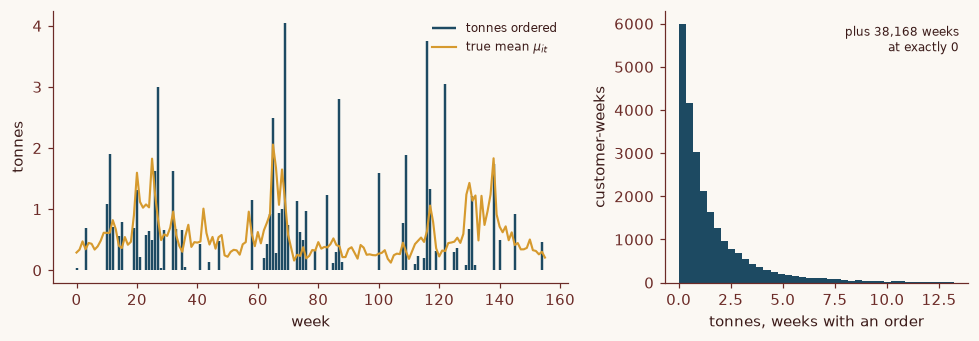

In [3]:
c = fallcolor.palette.discrete("default")
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1.7, 1]})
i = int(np.argsort(y.mean(axis=1))[S // 2])  # the median customer by average volume
a.vlines(np.arange(T), 0, y[i], color=c[0], lw=1.6, label="tonnes ordered")
a.plot(mu[i], color=c[1], lw=1.4, label=r"true mean $\mu_{it}$")
a.set(xlabel="week", ylabel="tonnes")
a.legend(fontsize=8, frameon=False)
positive = y[y > 0]
b.hist(positive, bins=np.linspace(0, np.quantile(positive, 0.995), 40), color=c[0])
b.set(xlabel="tonnes, weeks with an order", ylabel="customer-weeks")
b.text(0.97, 0.95, f"plus {(y == 0).sum():,} weeks\nat exactly 0", transform=b.transAxes, ha="right", va="top", fontsize=8)
fig.tight_layout()
plt.show()

<strong>Figure 1 | An intermittent target.</strong> Left: the synthetic customer with the median average volume; bars are tonnes ordered, the line is the true mean $\mu_{it}$, which never reaches zero although most weeks do. Right: tonnes in every customer-week with an order; the $38{,}168$ weeks at zero are not drawn.

### What each loss aims at

A loss decides which summary of the target a model estimates. To see which, find the constant forecast that minimises each loss on a sample from one customer type: an order every other week on average ($\lambda = 0.5$), $1\text{ t}$ per order ($\tau = 1\text{ t}$).

In [4]:
rng = np.random.default_rng(0)
lam0, tau0 = 0.5, 1.0  # an order every other week on average, 1 t per order
n0 = rng.poisson(lam0, 200_000)
y0 = np.where(n0 > 0, rng.gamma(np.maximum(n0, 1) * ALPHA, tau0 / ALPHA), 0.0)
losses = {
    "absolute error": lambda f: np.abs(y0 - f).mean(),
    "squared error": lambda f: ((y0 - f) ** 2).mean(),
    "squared error on log1p": lambda f: ((np.log1p(y0) - np.log1p(f)) ** 2).mean(),
    "Tweedie deviance, p = 1.5": lambda f: mean_tweedie_deviance(y0, np.full_like(y0, f), power=1.5),
}
print(f"sample mean {y0.mean():.3f} t, sample median {np.median(y0):.3f} t; best constant forecast (t):")
pd.Series({k: minimize_scalar(f, bounds=(1e-6, 2), method="bounded").x for k, f in losses.items()}).round(3)

sample mean 0.498 t, sample median 0.000 t; best constant forecast (t):


absolute error               0.000
squared error                0.498
squared error on log1p       0.317
Tweedie deviance, p = 1.5    0.498
dtype: float64

- **Absolute error** is minimised by the median, which is $0$ whenever more than half the weeks are empty. A model trained or selected on mean absolute error (MAE) is pushed towards forecasting nothing.
- **Squared error on $\log(1+y)$**, back-transformed with $e^{z} - 1$, gives $0.317\text{ t}$, which is $1 - 0.317/0.498 = 36\%$ below the mean. It estimates the mean of $\log(1+y)$, and because the logarithm is concave, transforming that back lands below the mean of $y$. [Log and Box–Cox transforms](../log-and-boxcox-transforms.qmd) covers this retransformation bias; with most of the mass at zero it is large.
- **Squared error** and the **Tweedie deviance** below both give the mean, $0.498\text{ t}$.

Ordering, packing and staffing usually need the mean, because means add up across customers and weeks. Squared error aims at it, but charges a $1\text{ t}$ miss for a customer who rarely orders the same as for one whose volume swings by tonnes, and nothing keeps its forecasts above zero.

## The Tweedie distribution

The generator is a compound Poisson–gamma distribution. Smyth and Jørgensen set out its properties for insurance, where the events are claims and the sizes their costs[^1]. With Poisson rate $\lambda$ and gamma sizes of mean $\tau$ and shape $\alpha$, the total $Y$ is zero with probability $e^{-\lambda}$ and otherwise continuous and positive, its mean is $\mu = \lambda\tau$, and its variance is

$$\operatorname{Var}(Y) = \phi\,\mu^{p}, \qquad p = \frac{\alpha + 2}{\alpha + 1}, \qquad \phi = \frac{\lambda^{1-p}\,\tau^{2-p}}{2-p}$$

where $p$ is the power of the variance function, between $1$ and $2$ because $\alpha > 0$, and $\phi$ is the dispersion in $\text{t}^{2-p}$, so that $\phi\mu^p$ is in $\text{t}^2$.

This is the Tweedie family of exponential dispersion models[^2], which generalise the error distributions of generalised linear models, with variance a power of the mean: $p = 0$ is the normal distribution, $p = 1$ the Poisson, $p = 2$ the gamma. Only $1 < p < 2$ gives a point mass at zero plus a continuous positive part. Exponential order sizes, $\alpha = 1$, give $p = 1.5$. A simulation of the customer type above checks the formulas:

In [5]:
p = (ALPHA + 2) / (ALPHA + 1)
phi = lam0 ** (1 - p) * tau0 ** (2 - p) / (2 - p)
print(f"p = {p}, phi = {phi:.3f}")
print(f"P(Y = 0): simulated {(y0 == 0).mean():.4f}, exp(-lambda) = {np.exp(-lam0):.4f}")
print(f"mean:     simulated {y0.mean():.4f}, lambda * tau = {lam0 * tau0:.4f}")
print(f"variance: simulated {y0.var():.4f}, phi * mu^p = {phi * (lam0 * tau0) ** p:.4f}")
print("HistGradientBoostingRegressor losses in scikit-learn", sklearn.__version__, ":", sorted(HistGradientBoostingRegressor._parameter_constraints["loss"][0].options))

p = 1.5, phi = 2.828
P(Y = 0): simulated 0.6066, exp(-lambda) = 0.6065
mean:     simulated 0.4980, lambda * tau = 0.5000
variance: simulated 0.9939, phi * mu^p = 1.0000
HistGradientBoostingRegressor losses in scikit-learn 1.9.0 : ['absolute_error', 'gamma', 'poisson', 'quantile', 'squared_error']


Simulation and formula agree, for example $0.994$ against $1.000$ for the variance.

### The deviance as a loss

With $p$ and $\phi$ fixed, fitting a Tweedie model by maximum likelihood means minimising its deviance. For $1 < p < 2$ and one customer-week,

$$d_p(y, \mu) = 2\left[\frac{y^{2-p}}{(1-p)(2-p)} - \frac{y\,\mu^{1-p}}{1-p} + \frac{\mu^{2-p}}{2-p}\right]$$

where $y \ge 0$ is the actual volume and $\mu > 0$ the forecast, both in tonnes, and $d_p$ is in $\text{t}^{2-p}$. At $y = 0$ it is $2\mu^{2-p}/(2-p)$: an empty week costs a forecast in proportion to what it promised, with no logarithm of zero. Its derivative,

$$\frac{\partial d_p}{\partial \mu} = 2\,\mu^{-p}\,(\mu - y),$$

has expected value zero at $\mu = \operatorname{E}[Y]$ for every $p$, so every Tweedie deviance is minimised by the mean, as squared error ($p = 0$) is. Gneiting calls such losses consistent scoring functions for the mean, and shows they are exactly the Bregman functions[^3]. What $p$ changes is the weight $\mu^{-p}$: errors count for less where the expected volume, and so the variance, is large.

Boosted trees and generalised linear models usually fit $\eta = \log\mu$, which keeps forecasts positive. The gradient with respect to $\eta$ is $2\mu^{1-p}(\mu - y)$. For the Poisson deviance, $p = 1$, that is $2(\mu - y)$, so a fit whose gradients sum to zero reproduces the training total. For other $p$ the balance is weighted by $\mu^{1-p}$, and totals can drift.

The installed scikit-learn 1.9.0 offers the boosting losses printed above: `"poisson"`, but no Tweedie power. Its linear `TweedieRegressor(power=p, link="log")` takes any $p$, as do LightGBM (`objective="tweedie"`) and XGBoost (`objective="reg:tweedie"`) through `tweedie_variance_power`. Yang, Qian and Zou found boosted Tweedie models more accurate than the linear one for insurance premiums[^4]. Below, the boosted model uses the Poisson deviance: the same mean, preserved totals, and less down-weighting of high-volume customers than $p = 1.5$.

## Same trees, different losses

The forecast is one week ahead for every customer. Each row is a customer-week with features known at the forecast origin: last week's volume, the mean over the last 4 and 26 weeks, the share of the last 26 weeks with an order, the mean size of those orders, and the target week as a sine–cosine pair. Weeks 26 to 103 train and the last 52 are held out; [Backtesting properly](../backtesting/backtesting_properly.ipynb) explains why a rolling origin would be better.

In [6]:
def features(y):
    "One row per customer-week; every column uses only weeks before the target week."
    last = pd.DataFrame(y).shift(1, axis=1)  # week t - 1
    roll = lambda frame, w: frame.T.rolling(w, min_periods=1).mean().T
    cols = {
        "lag_1": last,
        "mean_4": roll(last, 4),
        "mean_26": roll(last, 26),
        "share_ordering_26": roll((last > 0).astype(float), 26),
        "size_26": roll(last.where(last > 0), 26),  # mean tonnes in weeks with an order
    }
    X = pd.concat({k: v.stack(future_stack=True) for k, v in cols.items()}, axis=1).rename_axis(["customer", "week"])
    week = X.index.get_level_values("week") % 52
    return X.assign(week_sin=np.sin(2 * np.pi * week / 52), week_cos=np.cos(2 * np.pi * week / 52))


X = features(y)
target, true_mean = pd.DataFrame(y).stack(), pd.DataFrame(mu).stack()
week = X.index.get_level_values("week")
train, test = (week >= 26) & (week < 104), week >= 104
print(f"train: weeks 26-103, {train.sum():,} rows; test: weeks 104-155, {test.sum():,} rows")

train: weeks 26-103, 31,200 rows; test: weeks 104-155, 20,800 rows


The model is `HistGradientBoostingRegressor`, as in [Gradient boosting for tabular time series](../forecast/gradient_boosting_for_time_series.ipynb), with the same settings for each loss. The scores suit a mean forecast:

- **Mean Tweedie deviance, $p = 1.5$**, the main score: minimised by the mean, defined at $y = 0$, weighted to this target's variance. It needs $\mu > 0$, so forecasts below $0.001\text{ t}$ are raised to that (`floored` counts them).
- **MSE**, also minimised by the mean, dominated by the largest weeks.
- **Total bias**: the forecast total over all held-out customer-weeks against the actual total, in per cent.
- **MAE**, for contrast: it is minimised by the median.

Reference rows: zero every week, each customer's 26-week mean, and the unknowable true mean $\mu_{it}$.

In [7]:
params = dict(max_iter=300, learning_rate=0.05, early_stopping=False, random_state=0)


def fit_three(X, target):
    "Same trees, same features, three losses; returns test-week forecasts in tonnes."
    Xtr, ytr, Xte = X[train], target[train], X[test]
    return {
        "squared error": HistGradientBoostingRegressor(loss="squared_error", **params).fit(Xtr, ytr).predict(Xte),
        "squared error on log1p": np.expm1(HistGradientBoostingRegressor(**params).fit(Xtr, np.log1p(ytr)).predict(Xte)),
        "Poisson deviance": HistGradientBoostingRegressor(loss="poisson", **params).fit(Xtr, ytr).predict(Xte),
    }


FLOOR = 0.001  # t; the deviance needs a positive forecast


def score(actual, pred):
    return {
        "Tweedie deviance": mean_tweedie_deviance(actual, np.maximum(pred, FLOOR), power=1.5),
        "MSE (t²)": mean_squared_error(actual, pred),
        "total bias (%)": 100 * (pred.sum() / actual.sum() - 1),
        "MAE (t)": mean_absolute_error(actual, pred),
        "floored": int((pred < FLOOR).sum()),
    }


actual = target[test].to_numpy()
forecasts = {
    "zero every week": np.zeros(len(actual)),
    "mean of last 26 weeks": X.loc[test, "mean_26"].to_numpy(),
    **fit_three(X, target),
    "true mean (unknowable)": true_mean[test].to_numpy(),
}
pd.DataFrame({name: score(actual, f) for name, f in forecasts.items()}).T.round(3)

,Tweedie deviance,MSE (t²),total bias (%),MAE (t),floored
zero every week,73.785,2.780,-100.000,0.608,20800.0
mean of last 26 weeks,2.627,1.982,0.178,0.715,279.0
squared error,2.344,1.848,1.133,0.694,41.0
squared error on log1p,2.442,1.857,-32.098,0.621,8.0
Poisson deviance,2.302,1.844,0.550,0.692,0.0
true mean (unknowable),1.987,1.332,0.431,0.604,0.0


The true mean scores $1.987$; the gap to the best model, $2.302$, is what the features cannot know. The Poisson deviance scores best of the three losses ($2.302$), squared error next ($2.344$) and the log1p target last ($2.442$).

The log1p model forecasts $32.1\%$ less volume than arrived, close to the constant forecast's $36\%$ shortfall above. Squared error and the Poisson loss are within $1.1\%$ and $0.6\%$. MSE barely separates the three ($1.844$ to $1.857$), hiding a one-third shortfall.

MAE ranks them backwards. Zero every week scores $0.608\text{ t}$, better than every fitted model and just behind the true mean's $0.604\text{ t}$; among the models, the most biased has the best MAE ($0.621\text{ t}$). Squared error also gave $41$ forecasts below $0.001\text{ t}$; a model of $\log\mu$ cannot.

One panel can favour a loss by chance, so here are five more, each from a different seed:

In [8]:
runs = []
for seed in range(1, 6):
    ys, _ = simulate(seed)
    ts = pd.DataFrame(ys).stack()
    for name, f in fit_three(features(ys), ts).items():
        runs.append({"seed": seed, "loss": name, **score(ts[test].to_numpy(), f)})
runs = pd.DataFrame(runs).melt(id_vars=["seed", "loss"], value_vars=["Tweedie deviance", "total bias (%)"])
runs.pivot_table(index=["variable", "loss"], columns="seed", values="value").round(3)

seed                                          1       2       3       4  \
variable         loss                                                     
Tweedie deviance Poisson deviance         2.321   2.267   2.353   2.300   
                 squared error            2.460   2.317   2.421   2.314   
                 squared error on log1p   2.451   2.403   2.516   2.459   
total bias (%)   Poisson deviance         0.928   1.670  -4.252  -1.929   
                 squared error            1.150   3.260  -4.193  -1.427   
                 squared error on log1p -34.128 -32.098 -35.554 -34.182   

seed                                          5  
variable         loss                            
Tweedie deviance Poisson deviance         2.333  
                 squared error            2.454  
                 squared error on log1p   2.489  
total bias (%)   Poisson deviance         0.879  
                 squared error            3.090  
                 squared error on log1p -33.665

The log1p target under-forecast the total by $32.1\%$ to $35.6\%$ every time. The Poisson deviance beat squared error on all five panels, by $0.014$ to $0.139$; its total bias ranged from $-4.3\%$ to $+1.7\%$, squared error's from $-4.2\%$ to $+3.3\%$. So the Poisson loss gives a small, consistent gain over squared error and positive forecasts; the log1p target's shortfall is large on every seed.

## Two-part models and Croston

A two-part, or hurdle, model splits the target as the generator does: a classifier for whether the customer orders at all, $\pi = P(y > 0)$, and a regression for the volume in weeks with an order, $m = \operatorname{E}[y \mid y > 0]$. Since $\operatorname{E}[y] = \pi\,m$, the mean forecast is their product, and each part can be read alone. The volume part is positive and skewed, which the gamma deviance ($p = 2$) suits; the Poisson deviance is fitted alongside, and both are checked against their training totals:

In [9]:
Xtr, ytr, Xte = X[train], target[train], X[test]
ordered = ytr > 0
p_order = HistGradientBoostingClassifier(**params).fit(Xtr, ordered)
size_gamma = HistGradientBoostingRegressor(loss="gamma", **params).fit(Xtr[ordered], ytr[ordered])
size_poisson = HistGradientBoostingRegressor(loss="poisson", **params).fit(Xtr[ordered], ytr[ordered])

print(f"training weeks with an order: {ordered.mean():.3f}; mean predicted probability {p_order.predict_proba(Xtr)[:, 1].mean():.3f}")
for name, m in [("gamma", size_gamma), ("Poisson", size_poisson)]:
    print(f"{name:>7} volume model, training weeks with an order: predicted total / actual total = {m.predict(Xtr[ordered]).sum() / ytr[ordered].sum():.3f}")

prob = p_order.predict_proba(Xte)[:, 1]
two_part = {"two-part, gamma volume": prob * size_gamma.predict(Xte), "two-part, Poisson volume": prob * size_poisson.predict(Xte)}
pd.DataFrame({name: score(actual, f) for name, f in two_part.items()}).T.round(3)

training weeks with an order: 0.388; mean predicted probability 0.388
  gamma volume model, training weeks with an order: predicted total / actual total = 0.917
Poisson volume model, training weeks with an order: predicted total / actual total = 1.000


,Tweedie deviance,MSE (t²),total bias (%),MAE (t),floored
"two-part, gamma volume",2.315,1.754,-8.057,0.666,0.0
"two-part, Poisson volume",2.295,1.801,0.511,0.689,0.0


The classifier's mean probability matches the share of training weeks with an order ($0.388$). The gamma volume model under-predicts its own training total by $1 - 0.917 = 8.3\%$; the Poisson one matches it ($1.000$). With $p = 2$ the gradient sum driven to zero is $\sum (1 - y/\mu)$, which balances ratios, not tonnes. On the held-out year the product inherits the shortfall, $8.1\%$, while the Poisson version has a total bias of $0.5\%$ and a deviance of $2.295$, the lowest of any fitted model here.

Croston's method, the classical forecast for intermittent demand, makes the same split by hand. Croston showed that exponential smoothing of intermittent demand gives inappropriate stock levels and proposed separate estimates of demand size and frequency[^5]; usually each is smoothed in weeks with an order, and the forecast is smoothed size over smoothed interval. Syntetos and Boylan compared it with a moving average, simple exponential smoothing and their own modification of it on 3000 automotive series, and found the modification most accurate out of sample[^6]. It is a fair per-series baseline; a boosted model can also use prices, promotions and other customers' orders.

## Key takeaways

- Intermittent targets have a point mass at zero and a long tail. The mean is the forecast that adds up, so choose a loss and a score minimised by the mean.
- Squared error on $\log(1+y)$ estimates something well below the mean: here it under-forecast total volume by $32.1$–$35.6\%$ on all six panels.
- MAE favours forecasting zero when most weeks are empty. Score with the Tweedie deviance and report the total bias.
- The compound Poisson–gamma, Tweedie with $1 < p < 2$, is zero with probability $e^{-\lambda}$, with mean $\lambda\tau$ and variance $\phi\mu^p$. Its deviance and the Poisson deviance are minimised by the mean; the Poisson deviance also preserves training totals.
- In scikit-learn 1.9.0 use `HistGradientBoostingRegressor(loss="poisson")`; for a chosen $p$, use LightGBM, XGBoost or `TweedieRegressor`. A two-part model gives the same mean with readable parts, but check its totals.

## References

[^1]: Smyth, G. K. & Jørgensen, B. Fitting Tweedie's compound Poisson model to insurance claims data: dispersion modelling. *ASTIN Bull.* **32**, 143–157 (2002). https://doi.org/10.2143/AST.32.1.1020
[^2]: Jørgensen, B. Exponential dispersion models. *J. R. Stat. Soc. B* **49**, 127–145 (1987). https://doi.org/10.1111/j.2517-6161.1987.tb01685.x
[^3]: Gneiting, T. Making and evaluating point forecasts. *J. Am. Stat. Assoc.* **106**, 746–762 (2011). https://doi.org/10.1198/jasa.2011.r10138
[^4]: Yang, Y., Qian, W. & Zou, H. Insurance premium prediction via gradient tree-boosted Tweedie compound Poisson models. *J. Bus. Econ. Stat.* **36**, 456–470 (2018). https://doi.org/10.1080/07350015.2016.1200981
[^5]: Croston, J. D. Forecasting and stock control for intermittent demands. *Oper. Res. Q.* **23**, 289–303 (1972). https://doi.org/10.1057/jors.1972.50
[^6]: Syntetos, A. A. & Boylan, J. E. The accuracy of intermittent demand estimates. *Int. J. Forecast.* **21**, 303–314 (2005). https://doi.org/10.1016/j.ijforecast.2004.10.001

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/lightgbm-cross-entropy-bounded-target.html"><span>Previous</span>Cross-entropy for bounded targets</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/log-and-boxcox-transforms.html"><span>Next</span>Log and Box–Cox transforms</a></div>
<!-- CURRICULUM_FOOTER_END -->